# 07 - A1: control acquisition berbasis co-motion

Notebook ini membaca keluaran pipeline untuk mengevaluasi eksperimen A1 dengan F1 sebagai parent. D1 tidak diaktifkan. Logika acquisition ada di `src/control_acquisition.py` dan penerapannya di `src/team_control.py`; notebook hanya memeriksa keluaran, membuat agregasi diagnostik, dan memvisualisasikannya.

**Hipotesis:** beberapa pergantian H/A didukung kedekatan tanpa hubungan gerak bola-pemain yang cukup konsisten. Co-motion dapat menurunkan kekuatan evidence itu. Ini proxy kontrol, bukan label acquisition atau probabilitas. Tidak menggunakan public GT, anotasi manual, atau target jumlah possession.

## 1. Mekanisme dan batas

Posisi normalized dikonversi ke meter memakai pitch dari config. Relative speed adalah perubahan vektor bola-minus-pemain terdekat per detik. Kedua endpoint harus teramati, ball motion andal, coverage cukup, dan dekat. Nearest player boleh berubah; kita tidak mengasumsikan slot atau titik terdekat sebagai identitas permanen.

| Parameter awal | Nilai | Makna |
|---|---|---|
| Window | 5 frame (0.2 s pada 25 FPS) | Trailing, sejarah penuh dalam blok frame/babak |
| Support minimum | 0.6 | Minimal 3 cue dari 5; cue saat ini wajib |
| Jarak maksimum | 2.5 m | Menggunakan skala jarak control lama sebagai hipotesis awal |
| Relative speed maksimum | 3 m/s | Hipotesis awal toleransi hubungan spasial, bukan hasil tuning |
| Player quality minimum | 0.65 | Gate kualitas; bukan confidence |

A1 mengalikan **selisih skor H/A lama** dengan support tim yang sedang unggul pada skor lama. Midpoint dan urutan H/A dipertahankan (dapat menjadi seri). Nilai gate 0 berarti dukungan belum cukup, bukan tim lawan pasti menguasai. Tidak ada state incumbent, hard minimum spell, atau transition discount baru. Hint lama, decoder, Live/Dead dan boundary tetap.

**Risiko:** passing dapat kehilangan dukungan meski possession tim tetap; nearest-player switch dapat memutus dukungan; kedua tim bisa memenuhi proxy pada contested ball; geometri dan co-motion masih berkaitan. Karena itu ini belum bukti controlled possession yang independen sepenuhnya.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'games.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.artifacts import list_runs,read_json,read_table
from src.pipeline import run_pipeline
pd.set_option('display.max_columns',None)
PARENT_RUN_ID='20261115_232213_442294_bf05582d'
runs=list_runs(project_dir=ROOT)
parent_dir=next(Path(r['path']) for r in runs if r['run_id']==PARENT_RUN_ID)
parent_manifest=read_json(parent_dir);parent_config=read_json(parent_dir,'config/model.json')
MODEL_CONFIG=ROOT/'config/a1.yaml';STORAGE_CONFIG=ROOT/'config/artifacts_a1.yaml'
config=yaml.safe_load(MODEL_CONFIG.read_text(encoding='utf-8-sig'))
check=deepcopy(config);acquisition_config=check['control'].pop('acquisition')
assert acquisition_config['enabled'] is True and check==parent_config
assert not config.get('live_dead',{}).get('context_stoppage',{}).get('enabled',False)
print('F1 parent:',PARENT_RUN_ID)
display(acquisition_config)
display(yaml.safe_load(STORAGE_CONFIG.read_text(encoding='utf-8-sig')))

{'enabled': True, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65}

{'root_dir': 'artifacts', 'submission_filename': 'baseline_a1.csv'}

F1 parent: 20261115_232213_442294_bf05582d


## 2. Run terpisah dan konfigurasi efektif

`RUN_A1=True` menjalankan pipeline penuh dan membuat folder run baru. Setelah contoh run selesai, default akan menjadi False dengan run ID yang dipatok. Dengan False, notebook tidak menghitung ulang model dan hanya membaca CSV/JSON. Snapshot model, storage, provenance, seluruh hasil core, dan validator berada di folder run tersebut.

In [2]:
RUN_A1 = False
A1_RUN_ID = "20261116_004013_734042_91dc7b4d"
if RUN_A1:
    result=run_pipeline(config,project_dir=ROOT,storage_config_path=STORAGE_CONFIG,
        execution_metadata={'experiment':'A1_comotion_control','parent_run_id':PARENT_RUN_ID,
                            'notebook':'notebooks/07_control_acquisition_experiment.ipynb','model_config_source':str(MODEL_CONFIG)})
    run_dir=Path(result.artifact_dir)
else:
    candidates=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path'],'config/model.json').get('control',{}).get('acquisition',{}).get('enabled',False)]
    if not candidates:raise RuntimeError('Belum ada run A1 selesai; gunakan RUN_A1=True')
    run_dir=next(Path(r['path']) for r in candidates if r['run_id']==A1_RUN_ID) if A1_RUN_ID else Path(candidates[-1]['path'])
manifest=read_json(run_dir)
assert manifest['status']=='completed' and read_json(run_dir,'config/model.json')==config
parent_pass=parent_manifest['final_core_pass'];core_pass=manifest['final_core_pass']
print('A1 run:',manifest['run_id'],'folder:',run_dir,'core:',core_pass)
display(read_json(run_dir,'submission/validator/result.json'))

{'status': 'passed', 'message': 'OK    baseline_a1.csv\n      199319 rows, frame 0..199318\n\n      label counts\n        H    90217   45.3%\n        A    65645   32.9%\n        D     2995    1.5%\n        X    40462   20.3%\n\n      reports 235 possessions of mean 26.5 s\n      (counted with each X as a gap; the scorer bridges abstentions inside a real\n       possession, so its count can be lower than this one)\n\nValid. Note this checks the format only -- it says nothing about whether the labels are right.\nScore it against the public ground truth with run_evaluation.py.'}

A1 run: 20261116_004013_734042_91dc7b4d folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_004013_734042_91dc7b4d core: initial


## 3. Akses tabel dan uji isolasi

Sumber utama:

- `features/initial/frames.csv`: frame, half, graded, posisi/kecepatan bola, posisi/jarak pemain terdekat.
- `core/<pass>/control/components.csv`: relative speed (m/s, NaN bila pair invalid), pair-valid, cue boolean, support [0,1], gate [0,1], kontribusi lama, legacy/adjusted scores, dan hint lama.
- `core/<pass>/control/metadata.json`: definisi, konfigurasi efektif, FPS/pitch dan batas proxy.
- `core/<pass>/fusion/state_log_scores.csv`: utility H/A/D setelah fusion, bukan probabilitas.
- `core/<pass>/decode/labels.csv` dan `result/labels.csv`: decoded versus final.
- `diagnostics/` dan `submission/diagnostics.json`: ringkasan produksi untuk perbandingan.

Join memakai frame yang unik dan identik. Jika fitur, quality, event, hint atau Live/Dead berubah, eksperimen tidak lagi terisolasi. Argmax D alami harus tetap sama karena F1 mempertahankan utility tim terbaik sama dengan Live; temporal D akhir masih dapat berubah akibat jalur H/A yang berubah.

In [3]:
def join_frame(left,right):
    assert left.frame.is_unique and right.frame.is_unique
    assert np.array_equal(np.sort(left.frame),np.sort(right.frame))
    assert not (set(left.columns)&set(right.columns)-{'frame'})
    return left.merge(right,on='frame',validate='one_to_one',sort=True)

paths=[('features/initial/frames.csv','features/initial/frames.csv'),
       ('features/initial/events.csv','features/initial/events.csv'),
       (f'core/{parent_pass}/quality/frames.csv',f'core/{core_pass}/quality/frames.csv'),
       (f'core/{parent_pass}/events/frames.csv',f'core/{core_pass}/events/frames.csv'),
       (f'core/{parent_pass}/fusion/transition_hint.csv',f'core/{core_pass}/fusion/transition_hint.csv'),
       (f'core/{parent_pass}/live_dead/frames.csv',f'core/{core_pass}/live_dead/frames.csv')]
isolation=[]
for old,new in paths:
    same_hash=parent_manifest['files'][old]['sha256']==manifest['files'][new]['sha256']
    if not same_hash:pd.testing.assert_frame_equal(read_table(parent_dir,old),read_table(run_dir,new),check_exact=True,check_dtype=False)
    isolation.append({'artifact':new,'same_sha256':same_hash,'values_identical':True})
display(pd.DataFrame(isolation))
features=read_table(run_dir,'features/initial/frames.csv')
t=features[['frame','half','graded','ball_ok','ball_speed2d_mps','nearest_h_m','nearest_a_m','set_piece_tag']].copy()
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/control/components.csv'))
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/quality/frames.csv')[['frame','ball_motion_reliable','player_quality_weight']])
old_control=read_table(parent_dir,f'core/{parent_pass}/control/scores.csv')
np.testing.assert_array_equal(t[['legacy_h_score','legacy_a_score']],old_control[['H','A']])
for name,folder,pass_name in [('f1',parent_dir,parent_pass),('a1',run_dir,core_pass)]:
    scores=read_table(folder,f'core/{pass_name}/fusion/state_log_scores.csv').rename(columns={k:f'{name}_{k}' for k in ['H','A','D']})
    t=join_frame(t,scores)
    t=join_frame(t,read_table(folder,'result/labels.csv').rename(columns={'label':f'{name}_final'}))
    t=join_frame(t,read_table(folder,f'core/{pass_name}/decode/labels.csv').rename(columns={'label':f'{name}_decoded'}))
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/fusion/control_components.csv')[['frame','forced_d']])
natural=t.graded&~t.forced_d
np.testing.assert_array_equal(t.a1_D,t.f1_D)
np.testing.assert_array_equal(t[['a1_H','a1_A']].max(axis=1),t[['f1_H','f1_A']].max(axis=1))
metadata=read_json(run_dir,f'core/{core_pass}/control/metadata.json')
display(metadata)
print('PASS: upstream and legacy control identity, unchanged hint/Live/Dead and unchanged best-team utility.')

,artifact,same_sha256,values_identical
0,features/initial/frames.csv,True,True
1,features/initial/events.csv,True,True
2,core/initial/quality/frames.csv,True,True
3,core/initial/events/frames.csv,True,True
4,core/initial/fusion/transition_hint.csv,True,True
5,core/initial/live_dead/frames.csv,True,True


{'acquisition': {'enabled': True, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65}, 'fps': 25.0, 'pitch_m': [105.3, 68.0], 'semantics': 'uncalibrated co-motion support, not possession labels or player identities', 'window': 'trailing fixed denominator; full window inside contiguous half/frame block; current cue required', 'relative_speed': 'norm of change in metric ball-minus-nearest-player vector times FPS; both endpoints reliable and near', 'limitations': 'nearest player can change; a switch can suppress support; quiet/contested play can support both teams; passes may lose support', 'application': 'contract legacy H/A gap by support of the legacy winning team; preserve midpoint and framewise order; legacy transition hint unchanged', 'disabled': 'exact legacy scores and hints; acquisition gates are 1 (bypass), not measured support'}

PASS: upstream and legacy control identity, unchanged hint/Live/Dead and unchanged best-team utility.


## 4. Verifikasi rumus dan gate yang tersimpan

Pemeriksaan ini memvalidasi keluaran pipeline; notebook tidak menggantikan estimator. Setiap kontribusi skor lama dapat ditelusuri. Pair invalid tidak boleh menghasilkan cue. Gate tidak boleh tetap aktif ketika cue saat ini hilang, dan sejarah tidak boleh melintasi babak.

In [4]:
for side in ('h','a'):
    np.testing.assert_allclose(t[[f'distance_{side}',f'tag_{side}',f'persistence_{side}',f'signed_margin_{side}','symmetric_prior']].sum(axis=1),t[f'legacy_{side}_score'],rtol=0,atol=1e-12)
    active=t[f'acquisition_gate_{side}'].gt(0)
    assert t.loc[active,f'acquisition_cue_{side}'].all()
    assert t.loc[active,f'pair_valid_{side}'].all()
    assert t.loc[active,'ball_ok'].all() and t.loc[active,'ball_motion_reliable'].all()
    assert t.loc[active,f'acquisition_support_{side}'].ge(acquisition_config['minimum_support_fraction']).all()
    assert t.loc[active,f'relative_speed_{side}_mps'].le(acquisition_config['maximum_relative_speed_mps']).all()
    assert t.loc[active,f'nearest_{side}_m'].le(acquisition_config['maximum_distance_m']).all()
    assert t.loc[active,'player_quality_weight'].ge(acquisition_config['minimum_player_quality']).all()
np.testing.assert_allclose(t[['adjusted_h_score','adjusted_a_score']].mean(axis=1),t[['legacy_h_score','legacy_a_score']].mean(axis=1),rtol=0,atol=1e-12)
np.testing.assert_allclose(t.adjusted_h_score-t.adjusted_a_score,(t.legacy_h_score-t.legacy_a_score)*t.winner_gate,rtol=0,atol=1e-12)
assert t.winner_gate.between(0,1).all()
for half in (1,2):
    first=t.index[t.half.eq(half)][:acquisition_config['window_frames']-1]
    assert t.loc[first,['acquisition_gate_h','acquisition_gate_a']].eq(0).all().all()
print('PASS: score reconstruction, gap contraction, current observation gates and half reset.')
display(t.loc[natural,['relative_speed_h_mps','relative_speed_a_mps','acquisition_support_h','acquisition_support_a','winner_gate']].describe())

,relative_speed_h_mps,relative_speed_a_mps,acquisition_support_h,acquisition_support_a,winner_gate
count,3.499600e+04,26626.000000,155923.000000,155923.000000,155923.000000
mean,3.424338e+00,3.751421,0.137113,0.101191,0.195162
std,5.063037e+00,6.072678,0.333579,0.293008,0.393203
min,2.921274e-13,0.000000,0.000000,0.000000,0.000000
25%,1.056955e+00,1.022359,0.000000,0.000000,0.000000
50%,2.185041e+00,2.316013,0.000000,0.000000,0.000000
75%,4.490682e+00,4.731018,0.000000,0.000000,0.000000
max,1.213150e+02,119.375708,1.000000,1.000000,1.000000


PASS: score reconstruction, gap contraction, current observation gates and half reset.


## 5. Perbandingan perilaku dari diagnostics pipeline

Penurunan short spell atau transisi belum berarti accuracy/spellF1 naik. Perhatikan juga perubahan median durasi, D, dan perubahan yang baru muncul setelah boundary refinement. D1 tidak masuk perbandingan ini.

In [5]:
rows=[]
for name,folder,pass_name in [('F1',parent_dir,parent_pass),('A1',run_dir,core_pass)]:
    diag=read_json(folder,'submission/diagnostics.json')
    core=read_json(folder,f'diagnostics/{pass_name}/core/dead_score_summary.json')
    seg=read_table(folder,'diagnostics/final/prediction/segment_summary.csv')
    tr=read_table(folder,'diagnostics/final/prediction/transition_counts.csv')
    ha=seg.loc[seg.label.isin(['H','A'])]
    rows.append({'model':name,'HA_spells':diag['possession_spells'],'HA_short_lt_2s':int(ha.segments_lt_2s.sum()),
        'median_HA_duration_s':diag['possession_median_s'],'HA_transitions':int(tr.loc[tr['from'].isin(['H','A'])&tr['to'].isin(['H','A']),'count'].sum()),
        'total_transitions':diag['total_transitions'],'natural_D_utility_wins':core['dead_wins_unforced'],
        'natural_D_frames':int(t.loc[natural,f'{name.lower()}_final'].eq('D').sum())})
comparison=pd.DataFrame(rows).set_index('model');display(comparison)
assert comparison.loc['F1','natural_D_utility_wins']==comparison.loc['A1','natural_D_utility_wins']
display(pd.crosstab(t.loc[natural,'f1_final'],t.loc[natural,'a1_final']))
display(pd.crosstab(t.loc[natural,'a1_decoded'],t.loc[natural,'a1_final']))

,HA_spells,HA_short_lt_2s,median_HA_duration_s,HA_transitions,total_transitions,natural_D_utility_wins,natural_D_frames
model,,,,,,,
F1,1070,523,2.04,1067,1070,169,63
A1,235,23,12.76,231,236,169,61


a1_final,A,D,H
f1_final,,,
A,46253,24,13437
D,26,37,0
H,19366,0,76780


a1_final,A,D,H
a1_decoded,,,
A,65645,0,2
D,0,59,0
H,0,2,90215


## 6. Cakupan support dan sensitivitas observasi

`winner_gate=0` menetralkan gap H/A, termasuk saat observasi tidak cukup. Ini bukan abstention X dan bukan bukti tim lain menguasai. Decoder tetap memilih jalur global. Jika sebagian besar gap hilang, model dapat tampak stabil hanya karena kekurangan evidence. Dukungan kedua tim bersamaan juga tidak boleh disebut acquisition yang pasti.

In [6]:
regimes=t.loc[natural].copy()
regimes['support_regime']=np.select([
    regimes.acquisition_gate_h.gt(0)&regimes.acquisition_gate_a.gt(0),
    regimes.acquisition_gate_h.gt(0),regimes.acquisition_gate_a.gt(0)],['both','H_only','A_only'],default='neither')
coverage=regimes.groupby(['half','support_regime']).agg(frames=('frame','size'),observed_fraction=('ball_ok','mean'),
    mean_winner_gate=('winner_gate','mean'),mean_ball_speed=('ball_speed2d_mps','mean'))
display(coverage)
regimes['changed']=regimes.f1_final.ne(regimes.a1_final)
regimes['gate_zero']=regimes.winner_gate.eq(0)
display(regimes.groupby(['ball_ok','ball_motion_reliable','gate_zero']).agg(frames=('frame','size'),changed_frames=('changed','sum')))
for half in (1,2):
    g=regimes.loc[regimes.half.eq(half)]
    print('Half',half)
    display(pd.crosstab(g.f1_final,g.a1_final))
print('Fraction natural frames with zero winning-team gate:',float(regimes.gate_zero.mean()))
print('Fraction observed/reliable natural frames with zero gate:',float(regimes.loc[regimes.ball_ok&regimes.ball_motion_reliable,'gate_zero'].mean()))

frames  observed_fraction  mean_winner_gate  \
half support_regime                                                
1    A_only            5996           1.000000          0.970180   
     H_only            9012           1.000000          0.963759   
     both              1498           1.000000          0.990254   
     neither          62961           0.486920          0.000000   
2    A_only            5551           1.000000          0.948298   
     H_only            7740           1.000000          0.961421   
     both              1754           1.000000          0.991334   
     neither          61411           0.482585          0.000000   

                     mean_ball_speed  
half support_regime                   
1    A_only                 2.582551  
     H_only                 2.699144  
     both                   3.437924  
     neither                8.572132  
2    A_only                 3.221936  
     H_only                 2.866767  
     both                   3.516936  
     neither                8.457160

frames  changed_frames
ball_ok ball_motion_reliable gate_zero                        
False   False                True        64079           18917
True    False                True          195              39
        True                 False       31005             154
                             True        60644           13743

a1_final,A,D,H
f1_final,,,
A,25093,0,6270
D,26,37,0
H,11687,0,36354


a1_final,A,D,H
f1_final,,,
A,21160,24,7167
H,7679,0,40426


Half 1
Half 2
Fraction natural frames with zero winning-team gate: 0.8011518505929208
Fraction observed/reliable natural frames with zero gate: 0.6616984364259294


## 7. Audit boundary decoder dari artefak

Semua transisi H/A dari decoder disajikan dengan dukungan pada jendela 5 frame setelah transisi, tanpa memilih boundary secara manual. `support_regime` dan gate bukan ground truth. Perbandingan jumlah transisi per babak memperlihatkan apakah efek tersebar. Bila boundary final bergeser, bandingkan label decoded/final pada section 5.

In [7]:
boundary_rows=[]
for name,folder,pass_name in [('F1',parent_dir,parent_pass),('A1',run_dir,core_pass)]:
    tr=read_table(folder,f'core/{pass_name}/decode/transitions.csv')
    ha=tr.loc[tr['from'].isin(['H','A'])&tr['to'].isin(['H','A'])]
    for r in ha.itertuples(index=False):
        g=t.loc[t.frame.between(int(r.frame),int(r.frame)+4)&t.half.eq(int(r.half))]
        side=str(r.to).lower()
        boundary_rows.append({'model':name,'half':r.half,'frame':r.frame,'from':getattr(r,'_2'),
            'to':r.to,'mean_destination_support':g[f'acquisition_gate_{side}'].mean(),
            'mean_winner_gate':g.winner_gate.mean(),'ball_observed_fraction':g.ball_ok.mean()})
boundaries=pd.DataFrame(boundary_rows)
display(boundaries.groupby(['model','half']).agg(transitions=('frame','size'),
    median_destination_support=('mean_destination_support','median'),mean_observed_fraction=('ball_observed_fraction','mean')))
display(boundaries.head(20))

transitions  median_destination_support  mean_observed_fraction
model half                                                                 
A1    1             115                         0.0                0.986087
      2             116                         0.0                0.956897
F1    1             538                         0.0                0.957993
      2             529                         0.0                0.931947

,model,half,frame,from,to,mean_destination_support,mean_winner_gate,ball_observed_fraction
0,F1,1,11242,A,H,0.0,0.0,1.0
1,F1,1,11264,H,A,0.0,0.0,1.0
2,F1,1,11468,A,H,1.0,1.0,1.0
3,F1,1,11537,H,A,0.0,0.0,1.0
4,F1,1,11582,A,H,0.0,0.0,1.0
5,F1,1,11701,H,A,0.0,0.2,1.0
6,F1,1,11815,A,H,1.0,1.0,1.0
7,F1,1,11885,H,A,0.0,0.0,1.0
8,F1,1,11905,A,H,0.0,0.0,1.0
9,F1,1,12424,H,A,0.0,0.0,1.0


## 8. Visualisasi kasus yang dipilih algoritma

Pilih frame observed dengan pengurangan gap terbesar, lalu tampilkan konteks +/-3 detik dalam babak yang sama. Ini contoh efek mekanisme, bukan bukti kesalahan baseline. Panel label membedakan decoded dan final agar efek refinement terlihat. Support/gate adalah bobot dukungan, bukan probabilitas.

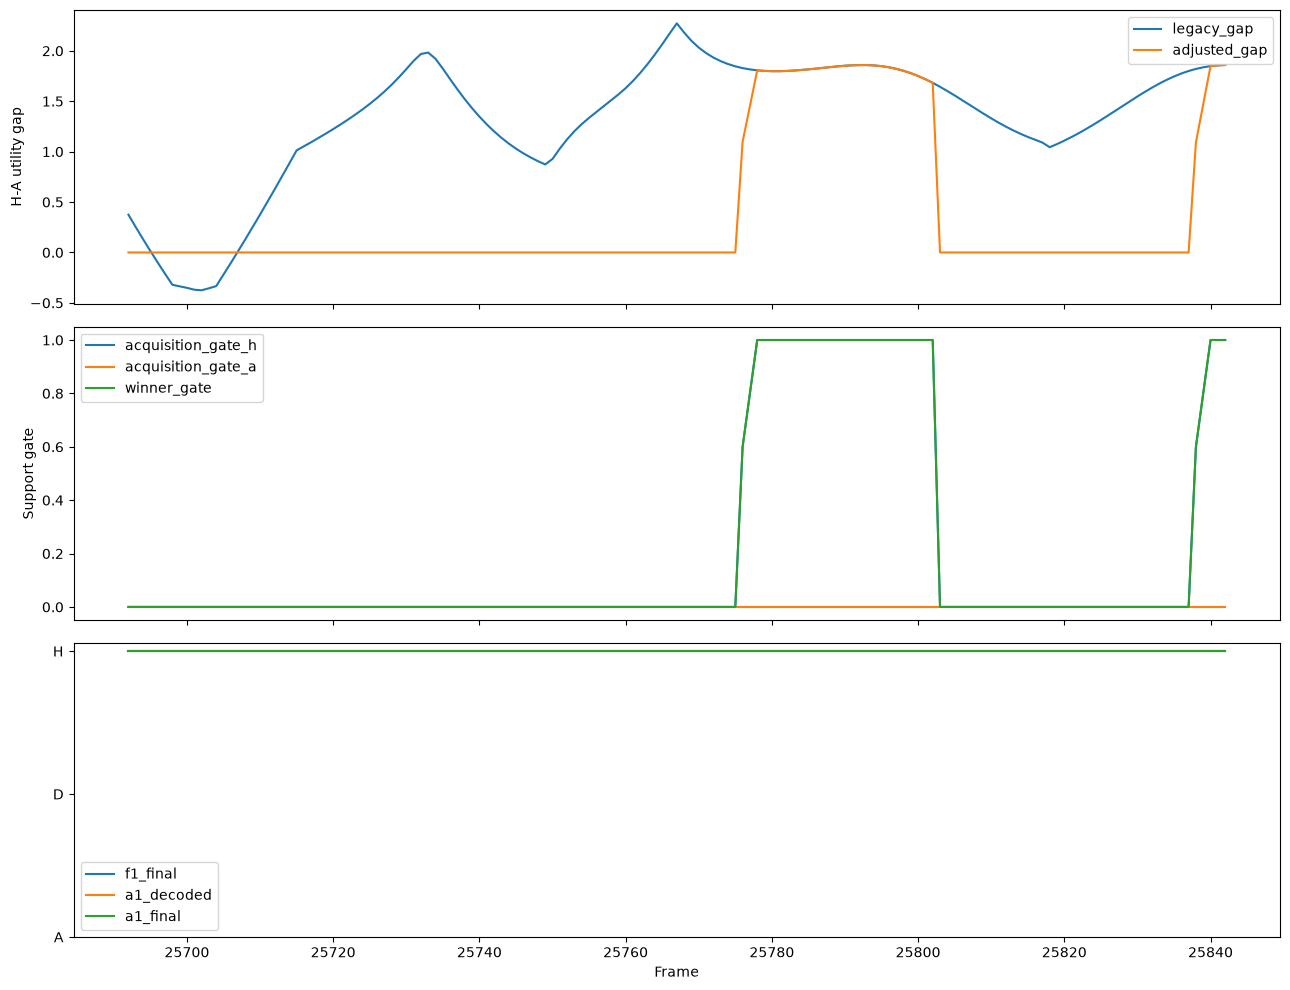

In [8]:
t['legacy_gap']=t.legacy_h_score-t.legacy_a_score
t['adjusted_gap']=t.adjusted_h_score-t.adjusted_a_score
reduction=t.legacy_gap.abs()-t.adjusted_gap.abs()
valid=natural&t.ball_ok&t.ball_motion_reliable
center=int(t.loc[valid].loc[reduction[valid].idxmax(),'frame'])
half=int(t.loc[t.frame.eq(center),'half'].iloc[0])
z=t.loc[t.frame.between(center-75,center+75)&t.half.eq(half)&~t.forced_d].copy()
fig,axes=plt.subplots(3,1,figsize=(13,10),sharex=True)
z.plot(x='frame',y=['legacy_gap','adjusted_gap'],ax=axes[0]);axes[0].set_ylabel('H-A utility gap')
z.plot(x='frame',y=['acquisition_gate_h','acquisition_gate_a','winner_gate'],ax=axes[1]);axes[1].set_ylabel('Support gate')
for label in ['f1_final','a1_decoded','a1_final']:
    axes[2].step(z.frame,z[label].map({'H':1,'A':-1,'D':0,'X':np.nan}),where='post',label=label)
axes[2].set_yticks([-1,0,1],['A','D','H']);axes[2].legend();axes[2].set_xlabel('Frame')
plt.tight_layout();plt.show()

## 9. Uji sintetis dan arah keputusan

Pengujian di `tests/test_control_acquisition.py` mencakup identitas legacy, ko-motion stabil, proximity/flyby tanpa support, contested ball, occlusion, kualitas rendah, pergantian babak/frame gap, satuan FPS/pitch, simetri H/A, cue causal dan turnover sah 0.8 detik. Tidak ada label sintetis yang berasal dari anotasi pertandingan.

| Jika ditemukan | Makna / keputusan |
|---|---|
| Legacy/upstream/hint/D utility berubah | Hentikan atribusi ke A1; periksa isolasi |
| Gap turun ketika winning team tidak punya co-motion support | Mekanisme sesuai desain; belum membuktikan turnover baseline salah |
| Mayoritas gap menjadi nol termasuk observasi baik | Risiko terlalu konservatif; audit passing/nearest switches sebelum adopsi |
| Short spell turun tetapi genuine short turnover sintetis hilang | Perbaiki representasi support, jangan mengejar angka spell |
| Kedua tim memiliki support | Co-motion belum memisahkan contested control; jangan klaim acquisition pasti |
| D final berubah padahal D utility sama | Efek jalur temporal bersama; audit decoded/final, jangan menyebut penambahan evidence D |
| Perubahan besar hanya pada boundary final | Audit refinement, bukan langsung menyalahkan estimator |
| Pola membaik pada indikator perilaku | Kandidat untuk validasi independen yang diizinkan, bukan klaim accuracy |

Jangan menggabungkan A1 dan D1 sebelum efek masing-masing dipahami. Jangan memilih parameter dari public GT atau proporsi possession yang terlihat realistis.

In [9]:
zero_fraction=float(regimes.gate_zero.mean())
observed_zero_fraction=float(regimes.loc[regimes.ball_ok&regimes.ball_motion_reliable,'gate_zero'].mean())
old_short=int(comparison.loc['F1','HA_short_lt_2s']);new_short=int(comparison.loc['A1','HA_short_lt_2s'])
display(Markdown(f"**Hasil run {manifest['run_id']}:** short H/A {old_short} -> {new_short}; "
    f"median H/A {comparison.loc['F1','median_HA_duration_s']:.2f} -> {comparison.loc['A1','median_HA_duration_s']:.2f} detik. "
    f"Gate winning team nol pada {zero_fraction:.1%} frame alami dan {observed_zero_fraction:.1%} frame alami observed/reliable. "
    "Isolasi dan gate lolos pemeriksaan. Ini indikator perilaku, bukan accuracy/spellF1."))
if observed_zero_fraction>0.5:
    display(Markdown('**Perhatian interpretasi:** lebih dari separuh frame observed/reliable kehilangan gap H/A. Stabilitas dapat berasal dari pelemahan evidence yang luas; A1 belum layak diadopsi hanya berdasarkan penurunan transisi. Periksa penerimaan bola, passing dan nearest-player switches sebagai keterbatasan proxy.'))
print('Parent:',PARENT_RUN_ID,'A1:',manifest['run_id'])

**Hasil run 20261116_004013_734042_91dc7b4d:** short H/A 523 -> 23; median H/A 2.04 -> 12.76 detik. Gate winning team nol pada 80.1% frame alami dan 66.2% frame alami observed/reliable. Isolasi dan gate lolos pemeriksaan. Ini indikator perilaku, bukan accuracy/spellF1.

**Perhatian interpretasi:** lebih dari separuh frame observed/reliable kehilangan gap H/A. Stabilitas dapat berasal dari pelemahan evidence yang luas; A1 belum layak diadopsi hanya berdasarkan penurunan transisi. Periksa penerimaan bola, passing dan nearest-player switches sebagai keterbatasan proxy.

Parent: 20261115_232213_442294_bf05582d A1: 20261116_004013_734042_91dc7b4d


## 10. Simpulan run A1 yang tersimpan

Run **20261116_004013_734042_91dc7b4d** dibandingkan dengan parent F1 **20261115_232213_442294_bf05582d**. Seluruh pemeriksaan isolasi lolos: fitur, quality, event, legacy control score, transition hint dan Live/Dead sama. D1 tidak diaktifkan. Validator format lolos; ini tidak memvalidasi accuracy label.

| Ukuran | F1 | A1 |
|---|---:|---:|
| HA spells | 1,070 | 235 |
| HA spells <2 s | 523 | 23 |
| Median HA duration (s) | 2.04 | 12.76 |
| HA transitions | 1,067 | 231 |
| Total transitions | 1,070 | 236 |
| Natural D utility wins | 169 | 169 |
| Natural final D frames | 63 | 61 |

**Yang terbukti:** kontraksi gap mengubah jalur temporal secara besar tanpa mengubah utility D atau utility Live terbaik. Dua frame perbedaan D akhir merupakan efek pipeline temporal/refinement, bukan tambahan evidence D.

**Batas utama:** gate winning team nol pada **80.1% frame alami**, termasuk **66.2% frame alami dengan bola teramati dan motion bola andal**. A1 menetralkan banyak evidence, bukan hanya segelintir crossover. Saat gap nol, decoder masih menghasilkan label lewat konteks dan biaya transisi. Karena itu, berkurangnya short spell belum membuktikan spurious turnover telah hilang; genuine turnover juga mungkin ikut hilang. Kelulusan turnover sintetis 0.8 detik hanya membuktikan skenario itu, bukan recall turnover pertandingan.

**Keputusan:** A1 tetap kandidat terpisah, belum menggantikan F1/v2 dan belum digabung dengan D1. Jangan mengadopsinya hanya karena statistik terlihat lebih mulus, atau memilih threshold baru dari jumlah possession maupun public GT.

**Pengembangan berikutnya:** pisahkan alasan gate nol (tidak dekat, pair tidak valid, relative speed tinggi, kualitas tidak cukup, atau history tidak cukup), dan uji passing, reception, loose ball serta nearest-player switches pada skenario sintetis tambahan. Jika kedekatan/motion tidak bisa membedakan acquisition dari kelanjutan possession dalam tim, revisi representasinya sebelum mengubah decoder. Pertimbangkan penggunaan acquisition untuk menilai bukti pergantian, dengan fallback evidence saat acquisition tidak teramati, dibanding menetralkan seluruh gap H/A. Itu eksperimen berikutnya yang harus diuji secara terisolasi, bukan asumsi bahwa A1 sudah meningkatkan accuracy.


## 11. Diagnosis lanjutan: mengapa gate nol?

Tujuannya menjelaskan perilaku A1 sebelum merancang A2. **Tidak ada perubahan rumus, threshold, hint, decoder, maupun boundary.** Pipeline kini menyimpan alasan gate nol, status evidence, episode gate nol, dan jarak ke support dalam babak yang sama. Skenario sintetis dihitung oleh estimator produksi di src lalu disimpan bersama run.

Angka 80.1% gate nol belum sama dengan 80.1% evidence dihapus: sebagian gap lama mungkin sudah nol. Audit baru memisahkan kedua keadaan itu.

`fail_*` adalah flag yang dapat tumpang tindih. `primary_reason_*` memilih satu alasan berdasarkan precedence di metadata; ini bukan urutan sebab yang paling penting. `unavailable` berarti data/history tidak cukup untuk menilai proxy. `observed_not_supporting_proxy` berarti syarat proxy tidak terpenuhi; itu bukan label negatif untuk possession atau acquisition.

| Primary reason | Cara membaca |
|---|---|
| missing_ball / unreliable_ball_motion | Observasi bola tidak cukup andal |
| low_player_quality / invalid_position | Coverage atau koordinat tidak cukup |
| not_near / previous_not_near | Endpoint sekarang/sebelumnya di luar radius |
| block_start / previous_observation_unavailable | Pair temporal tidak dapat dinilai |
| relative_speed_high | Hubungan bola-nearest point berubah lebih cepat dari ambang |
| insufficient_history / insufficient_support | Jendela belum penuh / cue di jendela belum cukup |
| supported | Gate positif |

`winner_tie=True` menandai skor lama seri. Pemilihan sisi diagnostik mengikuti pemilihan gate yang sudah ada (gate terbesar; H bila gate sama), bukan klaim bahwa home menguasai bola.

In [10]:
AUDIT_MODEL_CONFIG=ROOT/'config/a1.yaml'
AUDIT_STORAGE_CONFIG=ROOT/'config/artifacts_a1.yaml'
audit_config=yaml.safe_load(AUDIT_MODEL_CONFIG.read_text(encoding='utf-8-sig'))
A1_ORIGINAL_RUN_ID=manifest['run_id']
a1_original_dir=run_dir
a1_original_manifest=manifest
assert audit_config==read_json(a1_original_dir,'config/model.json')
print('Unchanged A1 model; diagnostic replay of:',A1_ORIGINAL_RUN_ID)

Unchanged A1 model; diagnostic replay of: 20261116_004013_734042_91dc7b4d


## 12. Replay A1 untuk menyimpan diagnostik

Setelah run contoh selesai, `RUN_A1_AUDIT=False` membaca run audit yang dipatok. Tidak ada A2 pada eksperimen ini. Setiap run tetap memiliki folder baru dan snapshot config/model.json serta config/storage.json.

In [11]:
RUN_A1_AUDIT = False
A1_AUDIT_RUN_ID = "20261116_010846_102998_57f79ee9"
if RUN_A1_AUDIT:
    audit_result=run_pipeline(audit_config,project_dir=ROOT,storage_config_path=AUDIT_STORAGE_CONFIG,
        execution_metadata={'experiment':'A1_readonly_diagnostic_replay','parent_run_id':A1_ORIGINAL_RUN_ID,
            'reference_f1_run_id':PARENT_RUN_ID,'notebook':'notebooks/07_control_acquisition_experiment.ipynb',
            'model_config_source':str(AUDIT_MODEL_CONFIG)})
    audit_dir=Path(audit_result.artifact_dir)
else:
    audit_runs=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path']).get('execution',{}).get('experiment')=='A1_readonly_diagnostic_replay']
    if not audit_runs:raise RuntimeError('Belum ada audit run; gunakan RUN_A1_AUDIT=True')
    audit_dir=next(Path(r['path']) for r in audit_runs if r['run_id']==A1_AUDIT_RUN_ID) if A1_AUDIT_RUN_ID else Path(audit_runs[-1]['path'])
audit_manifest=read_json(audit_dir);audit_pass=audit_manifest['final_core_pass']
assert audit_manifest['status']=='completed'
assert read_json(audit_dir,'config/model.json')==audit_config
print('Audit run:',audit_manifest['run_id'],'folder:',audit_dir)
display(read_json(audit_dir,'submission/validator/result.json'))

{'status': 'passed', 'message': 'OK    baseline_a1.csv\n      199319 rows, frame 0..199318\n\n      label counts\n        H    90217   45.3%\n        A    65645   32.9%\n        D     2995    1.5%\n        X    40462   20.3%\n\n      reports 235 possessions of mean 26.5 s\n      (counted with each X as a gap; the scorer bridges abstentions inside a real\n       possession, so its count can be lower than this one)\n\nValid. Note this checks the format only -- it says nothing about whether the labels are right.\nScore it against the public ground truth with run_evaluation.py.'}

Audit run: 20261116_010846_102998_57f79ee9 folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_010846_102998_57f79ee9


## 13. Pemeriksaan identitas perilaku

Pemeriksaan hash berikut harus lolos sebelum interpretasi audit. Components control dan metadata berubah karena kolom penjelasan baru; seluruh kolom components lama diperiksa satu per satu. CSV submission harus identik byte demi byte.

In [12]:
same_paths=['features/initial/frames.csv','features/initial/events.csv','result/labels.csv']
for stage,filename in [('quality','frames.csv'),('events','frames.csv'),('control','frames.csv'),('control','scores.csv'),
                       ('control','transition_hint.csv'),('live_dead','frames.csv'),('fusion','state_log_scores.csv'),
                       ('fusion','transition_hint.csv'),('fusion','stop_hint.csv'),('fusion','restart_hint.csv'),
                       ('decode','labels.csv'),('decode','transitions.csv')]:
    same_paths.append(f'core/{{pass_name}}/{stage}/{filename}')
identity=[]
for template in same_paths:
    old_path=template.format(pass_name=core_pass);new_path=template.format(pass_name=audit_pass)
    same=a1_original_manifest['files'][old_path]['sha256']==audit_manifest['files'][new_path]['sha256']
    assert same,new_path
    identity.append({'artifact':new_path,'identical_sha256':same})
old_submission=read_json(a1_original_dir,'submission/write/result.json')
new_submission=read_json(audit_dir,'submission/write/result.json')
assert old_submission['sha256']==new_submission['sha256']
old_components=read_table(a1_original_dir,f'core/{core_pass}/control/components.csv')
audit_components=read_table(audit_dir,f'core/{audit_pass}/control/components.csv')
pd.testing.assert_frame_equal(old_components,audit_components[old_components.columns],check_exact=True)
display(pd.DataFrame(identity))
print('PASS: all legacy components, scores, hints, decoded/final labels and submission bytes identical.')

,artifact,identical_sha256
0,features/initial/frames.csv,True
1,features/initial/events.csv,True
2,result/labels.csv,True
3,core/initial/quality/frames.csv,True
4,core/initial/events/frames.csv,True
5,core/initial/control/frames.csv,True
6,core/initial/control/scores.csv,True
7,core/initial/control/transition_hint.csv,True
8,core/initial/live_dead/frames.csv,True
9,core/initial/fusion/state_log_scores.csv,True


PASS: all legacy components, scores, hints, decoded/final labels and submission bytes identical.


## 14. Gate nol: informasi memang hilang atau gap sudah nol?

Keluaran produksi berada di `diagnostics/final/acquisition/`: frames.csv, zero_reason_summary.csv, failure_flag_summary.csv, zero_episodes.csv, boundary_support.csv dan summary.json. Reasons dan status per tim juga ada di `core/<pass>/control/components.csv`.

`removed_gap` adalah pengurangan besar selisih utility H/A, bukan banyaknya kesalahan yang diperbaiki. Gap nonzero memakai toleransi diagnostik 1e-12. Jarak support dihitung di dalam babak dengan natural support, satuan frame (bagi FPS untuk detik); NaN berarti tidak ada support pada arah itu. Jarak ke support masa depan hanya untuk diagnosis dan tidak masuk scorer.

In [13]:
audit_prefix='diagnostics/final/acquisition'
audit_summary=read_json(audit_dir,f'{audit_prefix}/summary.json')
audit_frames=read_table(audit_dir,f'{audit_prefix}/frames.csv')
audit_reasons=read_table(audit_dir,f'{audit_prefix}/zero_reason_summary.csv')
audit_flags=read_table(audit_dir,f'{audit_prefix}/failure_flag_summary.csv')
audit_episodes=read_table(audit_dir,f'{audit_prefix}/zero_episodes.csv')
audit_boundaries=read_table(audit_dir,f'{audit_prefix}/boundary_support.csv')
display(audit_summary)
display(audit_reasons.sort_values('frames',ascending=False))
display(audit_flags.sort_values('frames',ascending=False).head(16))
print('Flags overlap: jangan menjumlahkannya sebagai jumlah frame unik.')
display(audit_reasons.groupby('winner_evidence_status')[['frames','legacy_gap_nonzero_frames','removed_gap_sum']].sum())

{'natural_frames': 155923, 'zero_gate_frames': 124918, 'zero_gate_already_zero_gap_frames': 31387, 'zero_gate_removed_nonzero_gap_frames': 93531, 'nonzero_legacy_gap_natural_frames': 124536, 'zero_gate_fraction_given_nonzero_gap': 0.7510358450568511, 'removed_gap_sum': 64175.78110808254, 'legacy_abs_gap_sum': 108174.2803172204, 'gap_nonzero_tolerance': 1e-12, 'semantics': 'descriptive proxy failures, not negative possession labels; primary reasons are exclusive by precedence; flags overlap', 'support_distance': 'within same half, natural support only, 0 at supported frame, NaN if no earlier/later support; future distances diagnostic only', 'tie_selection': 'legacy tie selects the larger gate, H on equal gates; winner_tie is explicit, not a home-control claim', 'episode_scope': 'contiguous zero winning-gate frames inside natural half; not labelled possession spells'}

,half,winner_evidence_status,winner_primary_reason,frames,legacy_gap_nonzero_frames,removed_gap_sum,ball_observed_fraction
5,1,unavailable,missing_ball,32304,16972,3205.500000,0.0
13,2,unavailable,missing_ball,31775,15761,3162.750000,0.0
1,1,observed_not_supporting_proxy,not_near,18644,18644,14475.764064,1.0
9,2,observed_not_supporting_proxy,not_near,18007,18007,14072.823454,1.0
3,1,observed_not_supporting_proxy,relative_speed_high,10230,10230,12165.396361,1.0
11,2,observed_not_supporting_proxy,relative_speed_high,9978,9978,11613.411339,1.0
8,2,observed_not_supporting_proxy,insufficient_support,996,996,1405.774743,1.0
0,1,observed_not_supporting_proxy,insufficient_support,944,944,1354.915081,1.0
2,1,observed_not_supporting_proxy,previous_not_near,667,667,680.265205,1.0
10,2,observed_not_supporting_proxy,previous_not_near,641,641,654.012120,1.0


,half,flag,frames,zero_frames_denominator,fraction
22,1,winner_fail_insufficient_support,62340,63206,0.986299
23,2,winner_fail_insufficient_support,60790,61712,0.985060
14,1,winner_fail_previous_observation_unavailable,32668,63206,0.516850
4,1,winner_fail_unreliable_ball_motion,32391,63206,0.512467
8,1,winner_fail_invalid_position,32304,63206,0.511091
2,1,winner_fail_missing_ball,32304,63206,0.511091
15,2,winner_fail_previous_observation_unavailable,32031,61712,0.519040
5,2,winner_fail_unreliable_ball_motion,31883,61712,0.516642
3,2,winner_fail_missing_ball,31775,61712,0.514892
9,2,winner_fail_invalid_position,31775,61712,0.514892


,frames,legacy_gap_nonzero_frames,removed_gap_sum
winner_evidence_status,,,
observed_not_supporting_proxy,60107,60107,56422.362367
unavailable,64811,33424,6930.067666


Flags overlap: jangan menjumlahkannya sebagai jumlah frame unik.


## 15. Perubahan label F1 ke A1 menurut alasan gate

Join ini membandingkan label dari dua pipeline yang sudah tersimpan. `changed` berarti berbeda, bukan salah atau benar. Tabel dipisah antara gap lama nonzero dan gap lama sudah nol agar propagasi temporal pada wilayah tanpa evidence tidak tercampur dengan penghapusan gap.

Persentase label berbeda di suatu kelompok tidak membuktikan alasan gate tersebut menyebabkan seluruh perbedaannya: Viterbi memakai konteks global. Tidak ada pelabelan manual atau penggunaan public GT.

In [14]:
audit_view=join_frame(audit_frames,t[['frame','f1_final','a1_final']])
assert np.array_equal(audit_view.final_label,audit_view.a1_final)
audit_view['changed']=audit_view.f1_final.ne(audit_view.a1_final)
audit_natural=audit_view.loc[audit_view.natural].copy()
label_groups=audit_natural.groupby(['winner_evidence_status','winner_primary_reason','legacy_gap_nonzero']).agg(
    frames=('frame','size'),changed_frames=('changed','sum'),removed_gap_sum=('removed_gap','sum'),
    median_nearest_support_frames=('nearest_winner_support_frames','median')).reset_index()
display(label_groups.sort_values('changed_frames',ascending=False))
display(audit_natural.groupby(['half','legacy_gap_nonzero']).agg(frames=('frame','size'),
    changed_frames=('changed','sum'),removed_gap_sum=('removed_gap','sum')))
print('Frame berubah tidak menjadi label correctness untuk memilih parameter.')

,winner_evidence_status,winner_primary_reason,legacy_gap_nonzero,frames,changed_frames,removed_gap_sum,median_nearest_support_frames
8,unavailable,missing_ball,True,32733,12687,6.368250e+03,233.0
1,observed_not_supporting_proxy,not_near,True,36651,9587,2.854859e+04,36.0
7,unavailable,missing_ball,False,31346,6230,0.000000e+00,523.0
3,observed_not_supporting_proxy,relative_speed_high,True,20208,3420,2.377881e+04,9.0
6,unavailable,low_player_quality,True,387,338,2.037253e+02,366.0
2,observed_not_supporting_proxy,previous_not_near,True,1308,241,1.334277e+03,14.0
4,supported,supported,True,31005,154,8.233511e+02,0.0
0,observed_not_supporting_proxy,insufficient_support,True,1940,91,2.760690e+03,2.0
5,unavailable,low_player_quality,False,40,40,1.022446e-13,1362.5
11,unavailable,unreliable_ball_motion,True,194,38,2.059972e+02,59.0


frames  changed_frames  removed_gap_sum
half legacy_gap_nonzero                                         
1    False                15373            3658     1.034658e-13
     True                 64094           14325     3.251299e+04
2    False                16014            2613     0.000000e+00
     True                 60442           12257     3.166280e+04

Frame berubah tidak menjadi label correctness untuk memilih parameter.


## 16. Episode gate nol, propagasi jalur dan boundary

Episode di bawah adalah rentang gate nol, bukan possession spell. Pilih episode dengan jumlah frame label berbeda terbanyak secara otomatis. Jarak ke support mengukur posisi dalam konteks temporal; jarak besar sendiri bukan bukti label salah.

Pada boundary decoder, support tim tujuan saat boundary bisa nol karena jalur global memakai evidence yang muncul belakangan. Bandingkan next/previous support distance sebelum menyebutnya bug timing atau menambah transition cost.

,episode_id,half,start_frame,end_frame,n_frames,duration_s,primary_reason_mode,unavailable_fraction,not_supporting_proxy_fraction,legacy_gap_nonzero_fraction,removed_gap_sum,ball_observed_fraction,decoded_final_disagreement_frames,changed_frames,median_nearest_support_frames
463,463,1,86594,88591,1998,79.92,missing_ball,0.870370,0.129630,0.858859,501.099942,0.130631,0,1772,510.0
465,465,1,88693,90651,1959,78.36,missing_ball,0.976519,0.023481,0.145993,98.695600,0.166922,0,1647,980.0
278,278,1,46646,48603,1958,78.32,missing_ball,0.959142,0.040858,0.319203,192.846037,0.042390,0,1357,931.5
898,898,2,175715,177064,1350,54.00,missing_ball,0.947407,0.052593,0.699259,218.494345,0.053333,0,1328,338.0
426,426,1,79873,81228,1356,54.24,missing_ball,0.928466,0.071534,0.905605,287.903433,0.073746,0,1146,433.5
664,664,2,135569,136727,1159,46.36,missing_ball,0.911993,0.088007,0.964625,302.154497,0.089733,0,940,416.0
419,419,1,78178,79157,980,39.20,missing_ball,0.498980,0.501020,0.502041,382.626957,0.502041,0,850,264.5
448,448,1,84046,84849,804,32.16,missing_ball,0.909204,0.090796,0.799751,152.364877,0.093284,0,788,360.0
900,900,2,177079,177940,862,34.48,missing_ball,0.726218,0.273782,1.000000,367.590983,0.274942,0,787,395.5
284,284,1,50231,51064,834,33.36,missing_ball,0.868106,0.131894,0.821343,201.153017,0.134293,0,747,209.0


transitions  median_previous_support  \
half destination_reason_at_boundary                                         
1    insufficient_support                      1                   4583.0   
     missing_ball                              2                    676.5   
     not_near                                 56                    278.0   
     previous_not_near                         8                    144.5   
     relative_speed_high                      30                    172.5   
     supported                                17                      0.0   
     unreliable_ball_motion                    1                    144.0   
2    insufficient_support                      1                    288.0   
     missing_ball                              6                    602.0   
     not_near                                 58                    185.5   
     previous_not_near                         9                    677.0   
     relative_speed_high                      26                     69.5   
     supported                                16                      0.0   

                                     median_next_support  
half destination_reason_at_boundary                       
1    insufficient_support                            2.0  
     missing_ball                                  328.0  
     not_near                                       41.0  
     previous_not_near                              21.5  
     relative_speed_high                            28.0  
     supported                                       0.0  
     unreliable_ball_motion                        278.0  
2    insufficient_support                            2.0  
     missing_ball                                  161.0  
     not_near                                       36.0  
     previous_not_near                              12.0  
     relative_speed_high                            34.0  
     supported                                       0.0

,previous_winner_support_frames,next_winner_support_frames,nearest_winner_support_frames
changed,,,
False,66.0,54.0,25.0
True,400.0,522.0,242.0


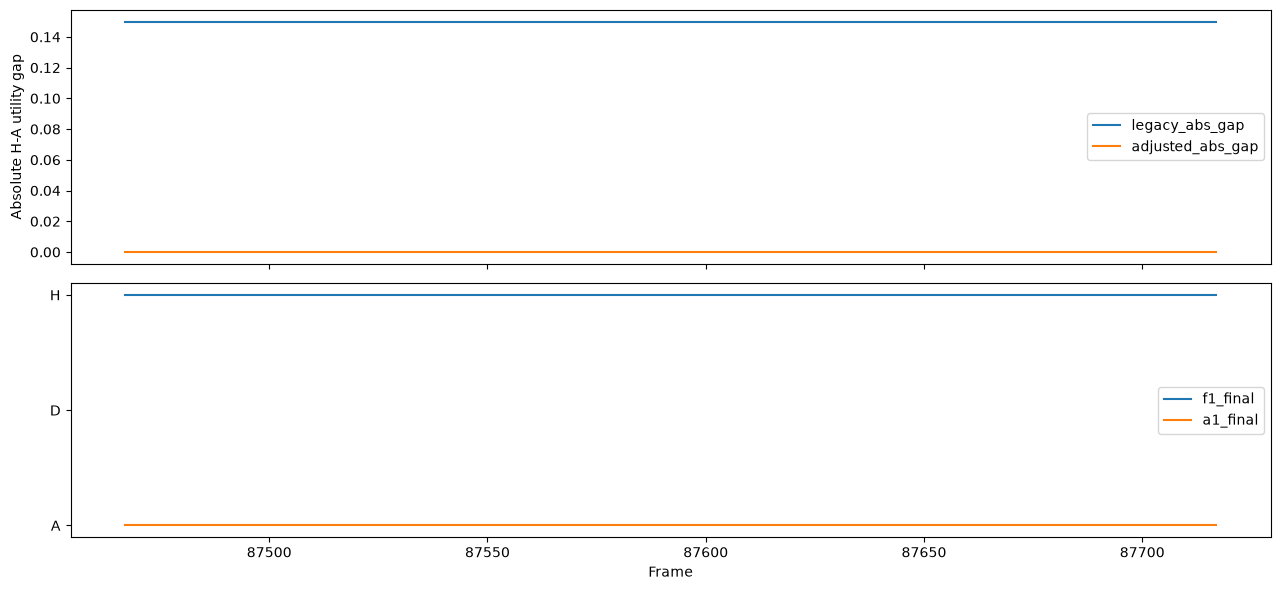

In [15]:
episode_changes=audit_natural.loc[audit_natural.zero_episode_id.ge(0)].groupby('zero_episode_id').agg(
    changed_frames=('changed','sum'),median_nearest_support_frames=('nearest_winner_support_frames','median'))
episode_audit=audit_episodes.merge(episode_changes,left_on='episode_id',right_index=True,validate='one_to_one')
display(episode_audit.sort_values('changed_frames',ascending=False).head(15))
display(audit_boundaries.groupby(['half','destination_reason_at_boundary']).agg(
    transitions=('frame','size'),median_previous_support=('previous_destination_support_frames','median'),
    median_next_support=('next_destination_support_frames','median')))
display(audit_natural.groupby('changed')[['previous_winner_support_frames','next_winner_support_frames','nearest_winner_support_frames']].median())
chosen=episode_audit.sort_values('changed_frames',ascending=False).iloc[0]
center=(int(chosen.start_frame)+int(chosen.end_frame))//2
w=audit_view.loc[audit_view.frame.between(center-125,center+125)&audit_view.half.eq(chosen.half)&audit_view.natural]
fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
w.plot(x='frame',y=['legacy_abs_gap','adjusted_abs_gap'],ax=axes[0]);axes[0].set_ylabel('Absolute H-A utility gap')
for label in ['f1_final','a1_final']:
    axes[1].step(w.frame,w[label].map({'H':1,'A':-1,'D':0,'X':np.nan}),where='post',label=label)
axes[1].set_yticks([-1,0,1],['A','D','H']);axes[1].legend();axes[1].set_xlabel('Frame')
plt.tight_layout();plt.show()

## 17. Skenario sintetis: acquisition vs continuation

Sumber: `diagnostics/acquisition_synthetic/summary.csv`, frames.csv dan metadata.json. Generator dan estimator berada di src. Kasus tidak menggunakan observasi atau label pertandingan.

Passing dalam tim dan nearest-player switch mempertahankan pemilik tim pada konstruksi skenario, meski support acquisition dapat nol. Reception/interception menguji pergantian sah termasuk interval singkat. Loose/contested phase tidak diberi expected owner; contested menguji bahwa kedua tim dapat memenuhi proxy. Occlusion menguji ketidaktersediaan evidence. Pemeriksaan label mengecualikan +/-6 frame di sekitar batas fase sintetis; lolosnya tes tidak mengukur ketepatan timing boundary pertandingan.

,scenario,passed,checked_label_frames,checked_label_matches,challenge_frames,challenge_zero_gate_fraction,challenge_unavailable_fraction,challenge_not_supporting_proxy_fraction,challenge_both_supported_fraction
0,same_team_pass,True,142,142,40,1.000000,0.0,1.000000,0.000
1,reception_turnover,True,155,155,90,0.033333,0.0,0.033333,0.000
2,short_interception,True,142,142,20,0.150000,0.0,0.150000,0.000
3,loose_ball,True,115,115,40,1.000000,0.0,1.000000,0.000
4,contested_ball,True,115,115,40,0.025000,0.0,0.025000,0.925
5,occlusion,True,142,142,40,1.000000,1.0,0.000000,0.000
6,nearest_player_switch,True,142,142,40,0.975000,0.0,0.975000,0.000


{'source': 'deterministic synthetic feature sequences only; no competition observations, labels or GT', 'expected_labels': 'scenario construction; loose/contested challenge phases unlabelled; +/-6 frames around phase boundaries excluded from label checks', 'scorer': 'production quality, team_control, live_dead, F1 fusion and temporal decoder; no new scoring logic in notebook', 'meaning': 'passing/switch/occlusion can lose acquisition support despite continued team possession; both-supported contested phase is not assigned a ground-truth owner', 'scope': 'behavioral specification checks, not match accuracy or turnover recall', 'fps': 25.0, 'pitch_m': [105.3, 68.0]}

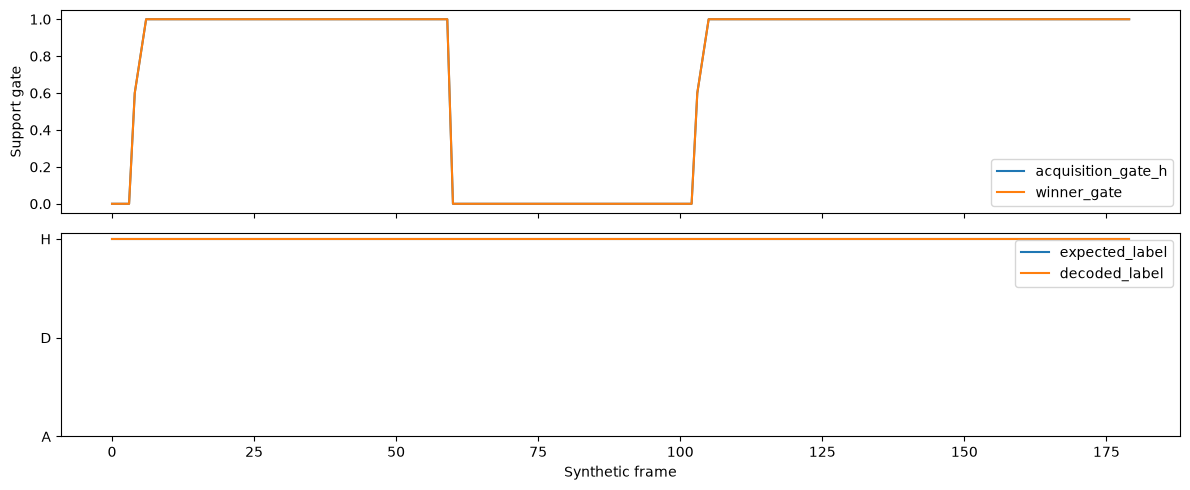

In [16]:
synthetic_summary=read_table(audit_dir,'diagnostics/acquisition_synthetic/summary.csv')
synthetic_frames=read_table(audit_dir,'diagnostics/acquisition_synthetic/frames.csv')
display(synthetic_summary)
display(read_json(audit_dir,'diagnostics/acquisition_synthetic/metadata.json'))
assert synthetic_summary.passed.all()
s=synthetic_frames.loc[synthetic_frames.scenario.eq('same_team_pass')]
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
s.plot(x='frame',y=['acquisition_gate_h','winner_gate'],ax=axes[0]);axes[0].set_ylabel('Support gate')
for label in ['expected_label','decoded_label']:
    axes[1].step(s.frame,s[label].map({'H':1,'A':-1,'D':0}),where='post',label=label)
axes[1].set_yticks([-1,0,1],['A','D','H']);axes[1].legend();axes[1].set_xlabel('Synthetic frame')
plt.tight_layout();plt.show()

## 18. Interpretasi audit dan keputusan A2

| Temuan | Arah keputusan |
|---|---|
| Banyak gate nol ternyata gap lama sudah nol | Koreksi pembacaan cakupan; jangan menyamakan gate nol dengan evidence yang dihapus |
| Gate nol dengan gap lama nonzero didominasi unavailable | Uji fallback untuk evidence yang tidak dapat dinilai; jangan menganggap absence of support sebagai bukti pergantian salah |
| Relative speed / not-near dominan pada observasi baik | Uji passing, reception dan pergantian nearest point; revisi representasi sebelum sekadar melonggarkan threshold |
| Label berbeda meluas pada gap lama nol | Ada propagasi jalur temporal; pisahkan dari lokasi penghapusan evidence |
| Boundary mendahului support tim tujuan | Periksa next-support distance dan objective; belum otomatis bug |
| Passing mempertahankan tim tetapi support hilang | Acquisition tidak setara dengan continuation; hindari memakai satu gate sebagai syarat universal seluruh evidence kontrol |
| Dua tim sama-sama supported | Proxy belum menyelesaikan contested possession |

**Belum ada A2 pada tahap ini.** Setelah diagnosis, kandidat terkecil adalah membedakan unavailable dari observed-not-supporting dan menguji fallback terhadap F1/A1 secara terisolasi. Jika tetap tidak dapat membedakan acquisition dari continuation, revisi representasi terlebih dahulu. Jangan menggabungkan D1, memilih threshold dari jumlah spell, atau memakai public GT untuk model selection.

In [17]:
reason_total=audit_reasons.groupby('winner_primary_reason')[['frames','legacy_gap_nonzero_frames','removed_gap_sum']].sum()
reason_nonzero=reason_total.sort_values('legacy_gap_nonzero_frames',ascending=False)
print('Alasan dominan pada zero-gate dengan gap lama nonzero:')
display(reason_nonzero.head(6))
display(Markdown(f"**Replay {audit_manifest['run_id']}:** skor, hint dan label identik dengan A1 asli. "
    f"Dari {audit_summary['zero_gate_frames']:,} zero-gate frame alami, "
    f"{audit_summary['zero_gate_already_zero_gap_frames']:,} sudah memiliki gap lama nol dan "
    f"{audit_summary['zero_gate_removed_nonzero_gap_frames']:,} kehilangan gap lama nonzero. "
    "Tabel alasan, episode, jarak support dan skenario sintetis menjadi dasar keputusan; tidak ada klaim accuracy/spellF1."))
print('A2 belum diimplementasikan; seluruh keluaran baru bersifat diagnostik.')

,frames,legacy_gap_nonzero_frames,removed_gap_sum
winner_primary_reason,,,
not_near,36651,36651,28548.587518
missing_ball,64079,32733,6368.250000
relative_speed_high,20208,20208,23778.807699
insufficient_support,1940,1940,2760.689825
previous_not_near,1308,1308,1334.277325
low_player_quality,427,387,203.725276


**Replay 20261116_010846_102998_57f79ee9:** skor, hint dan label identik dengan A1 asli. Dari 124,918 zero-gate frame alami, 31,387 sudah memiliki gap lama nol dan 93,531 kehilangan gap lama nonzero. Tabel alasan, episode, jarak support dan skenario sintetis menjadi dasar keputusan; tidak ada klaim accuracy/spellF1.

Alasan dominan pada zero-gate dengan gap lama nonzero:
A2 belum diimplementasikan; seluruh keluaran baru bersifat diagnostik.


## 19. Simpulan audit dan rancangan langkah berikutnya

Audit run **20261116_010846_102998_57f79ee9** memakai konfigurasi A1 yang sama dengan run asli. Pemeriksaan hash membuktikan fitur, quality, event, seluruh skor/hint, decoded/final labels, serta CSV submission identik. Seluruh kolom components lama juga identik. Hasil baru hanya berupa penjelasan dan diagnostik.

**Koreksi pembacaan cakupan:** dari 124,918 zero-gate frame alami, **31,387 sudah memiliki gap lama nol**, sedangkan **93,531 kehilangan gap lama nonzero**. Jadi angka 80.1% gate nol tidak boleh disebut 80.1% evidence dihapus. Namun peredaman tetap luas: **75.1% frame alami yang semula memiliki gap nonzero** dinetralkan.

| Alasan utama pada zero gate | Frame dengan gap lama nonzero | Jumlah besar gap yang dihapus (utility-frame) |
|---|---:|---:|
| not_near | 36,651 | 28,548.59 |
| missing_ball | 32,733 | 6,368.25 |
| relative_speed_high | 20,208 | 23,778.81 |

Alasan utama bersifat eksklusif berdasarkan precedence, bukan ranking kausal; flag yang tumpang tindih tersedia terpisah. Jumlah frame dan jumlah utility yang hilang memberi sudut pandang berbeda. Missing ball memengaruhi banyak frame tetapi not_near/relative_speed_high menghapus gap total yang lebih besar. Hasil ini bukan dasar memilih bobot berdasarkan target statistik.

**Propagasi temporal nyata pada perbandingan model:** ada label yang berbeda saat gap lama memang sudah nol. Median jarak ke support terdekat pada kelompok label berubah adalah 242 frame, dibanding 25 frame pada kelompok tidak berubah. Episode zero-gate yang ditampilkan mencakup rentang puluhan detik (misalnya 79.92 detik); episode ini bukan possession spell atau label ketepatan. Sebagian besar episode panjang yang tampil didominasi missing ball. Ini konsisten dengan pengaruh konteks global melalui wilayah yang minim evidence, tetapi tidak mengidentifikasi label mana yang benar.

**Counterexample sintetis:** pada passing dalam tim, gate nol selama seluruh 40 frame fase passing meskipun expected team tetap H; decoder tetap mempertahankan H lewat konteks. Pada pergantian nearest point, gate nol pada 97.5% fase. Pada occlusion, seluruh fase berstatus unavailable. Pada contested phase, kedua tim supported pada 92.5% fase. Semua tujuh skenario lolos pemeriksaan yang ditentukan. Artinya, proxy support tidak sama dengan acquisition, continuation atau owner; hasil sintetis ini tidak boleh dipakai untuk memberi label passing pada frame pertandingan tertentu.

**Diagnosis:** A1 mencampurkan kemampuan menilai acquisition dengan syarat mempertahankan seluruh gap kontrol, termasuk dukungan tag. Ketidaktersediaan co-motion tidak membuktikan bahwa evidence tag harus dihapus; observasi yang tidak memenuhi co-motion juga tidak membuktikan possession tim berakhir. Statistik A1 yang lebih mulus belum cukup untuk adopsi.

**Rancangan berikutnya, belum diimplementasikan:**

1. Uji ablation terkecil **fallback hanya ketika status unavailable**: pertahankan evidence lama pada kondisi yang proxy-nya tidak dapat dinilai. Pertahankan scoring pada observed-not-supporting agar efek fallback dapat diukur sendiri. Hipotesisnya mengurangi penghapusan prior tag saat observasi hilang; ini tidak dijanjikan menyelesaikan not_near/relative-speed.
2. Jika pelemahan pada observasi baik tetap mendominasi, revisi penggunaan acquisition agar membedakan **kelanjutan possession dalam tim** dari **bukti tim penantang mengambil kontrol**. Audit kontribusi tag, proximity/persistence dan hint yang sudah ada sebelum menambah mekanisme baru. Hindari mengalikan seluruh gap dengan satu syarat acquisition universal.
3. Uji kandidat dengan skenario sintetis yang sama, tambahkan kasus passing yang bersinggungan dengan lawan serta turnover saat occlusion. Bandingkan F1, A1 dan kandidat secara terpisah; jangan menggabungkan D1 atau mengubah decoder dalam eksperimen yang sama.
4. Jika skor dan perilaku kandidat sesuai desain, perlakukan sebagai kandidat validasi independen yang diizinkan. Penurunan short spell, label berubah, atau jumlah possession bukan bukti accuracy/spellF1 naik dan bukan target tuning public GT.

**Keputusan sekarang:** belum mengadopsi A1 dan belum membuat A2. Diagnosis menghasilkan dasar yang lebih jelas untuk ablation fallback dan perbaikan representasi acquisition/continuation berikutnya.
